# Proyecto U3–U5 · 2. Aprendizaje con datos limitados (U3)

Tema 2: **lesiones de piel, del dermatoscopio al móvil**. Este notebook parte del *baseline* (`01_baseline.ipynb`):
usa la misma tabla, las mismas features y el mismo modelo de referencia, y aplica estas técnicas:

| Apartado | Técnica | Nivel |
|---|---|---|
| Compensar con la función de pérdida | Cross-entropy ponderada | 1 |
| | Focal loss | 1 |
| | Ajuste de logits | 2 |
| Compensar con los datos | Batches balanceados | 1 |
| | Mezcla de imágenes | 2 |
| Evaluar una representación | Comprobación de representaciones (t-SNE) | — |
| Pocos datos | CLIP zero-shot | 1 |
| | Curva de 1 a 20 melanomas | — |

**Cómo se compara:** todas las técnicas se entrenan con el train del dermatoscopio y se evalúan en los dos tests,
con las mismas métricas que el baseline. La métrica principal es la **macro-F1 del test del dermatoscopio**
(es donde se trabaja la U3); el móvil se muestra como información secundaria. En el móvil, las métricas se calculan
solo con sus 5 clases.

**Antes de ejecutar:** hay que haber ejecutado `01_baseline.ipynb`, que deja en `trabajo/` la tabla, las clases,
las features y `baseline.json`. La mezcla de imágenes necesita además las imágenes en `datos/`.

## 0 · Configuración

In [38]:
import os, sys, copy, random, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from PIL import Image
from torch.utils.data import Dataset, DataLoader, TensorDataset, WeightedRandomSampler
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix, silhouette_score
from sklearn.manifold import TSNE
warnings.filterwarnings('ignore', message='xFormers')  # DINOv2 avisa de que falta xFormers, que es opcional

TRABAJO = Path(os.environ.get('VAAP_TRABAJO', 'trabajo'))
DATOS = Path(os.environ.get('VAAP_DATOS', 'datos'))
IMG = Path('memoria/images')                 # las figuras se guardan aquí para la memoria
U3 = TRABAJO / 'u3'                          # resultados intermedios de este notebook
for d in (TRABAJO, DATOS, IMG, U3):
    d.mkdir(parents=True, exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
NUM_WORKERS = 0 if sys.platform == 'darwin' else min(8, os.cpu_count() or 2)  # en macOS los workers no ven las clases del notebook
SEMILLA = 0

def sembrar(s=SEMILLA):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

sembrar()
print('Dispositivo:', DEVICE, '| resultados en:', TRABAJO.resolve())

Dispositivo: mps | resultados en: /Users/ivandominguez/Desktop/project_skin_wounds/trabajo


### Funciones comunes

Las mismas que en el baseline (con MobileNetV3 añadida en `cargar_modelo`), para que todo se entrene igual.

In [39]:
class Imagenes(Dataset):
    def __init__(self, rutas, transform, alterar=None):
        self.rutas, self.transform, self.alterar = list(rutas), transform, alterar
    def __len__(self):
        return len(self.rutas)
    def __getitem__(self, i):
        img = Image.open(self.rutas[i]).convert('RGB')
        if self.alterar is not None:
            img = self.alterar(img)
        return self.transform(img)

def cargar_modelo(nombre):
    if nombre == 'resnet50':        # supervisado en ImageNet
        pesos = torchvision.models.ResNet50_Weights.IMAGENET1K_V2
        modelo = torchvision.models.resnet50(weights=pesos)
        modelo.fc = torch.nn.Identity()
        return modelo, pesos.transforms()
    if nombre == 'dinov2_vits14':   # auto-supervisado (3.3)
        modelo = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14', verbose=False)
        tf = T.Compose([T.Resize(224, interpolation=T.InterpolationMode.BICUBIC), T.CenterCrop(224), T.ToTensor(),
                        T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))])
        return modelo, tf
    if nombre == 'clip_vitb32':     # imagen + texto (3.2, 4.2)
        import open_clip
        modelo, _, tf = open_clip.create_model_and_transforms('ViT-B-32', pretrained='laion2b_s34b_b79k')
        return modelo.visual, tf
    if nombre == 'mobilenet_v3':    # ligera, pensada para ejecutarse en el móvil
        pesos = torchvision.models.MobileNet_V3_Large_Weights.IMAGENET1K_V2
        modelo = torchvision.models.mobilenet_v3_large(weights=pesos)
        modelo.classifier = torch.nn.Identity()
        return modelo, pesos.transforms()
    raise ValueError(nombre)

def estandarizar(X_entreno, *otros):
    esc = StandardScaler().fit(X_entreno)
    return [esc.transform(X_entreno)] + [esc.transform(o) for o in otros]

def normalizar(X):
    return X / np.linalg.norm(X, axis=1, keepdims=True)

def entrenar_cabeza(X, y, n_clases, perdida='ce', muestreo=None, epocas=30, lote=256, lr=1e-3, gamma=1.0):
    # perdida: 'ce' | 'ce_ponderada' | 'focal' | 'label_smoothing'
    # muestreo: None | 'sobremuestreo' | 'submuestreo' | 'batch_balanceado'
    X, y = torch.as_tensor(X, dtype=torch.float32), torch.as_tensor(y, dtype=torch.long)
    conteo = torch.bincount(y, minlength=n_clases).float()
    pesos_clase = (conteo.sum() / (n_clases * conteo.clamp(min=1))).to(DEVICE)

    if muestreo == 'submuestreo':               # cada clase se queda con tantos ejemplos como la más pequeña
        m = int(conteo[conteo > 0].min())
        idx = torch.cat([torch.nonzero(y == c).flatten()[torch.randperm(int(conteo[c]))[:m]]
                         for c in range(n_clases) if conteo[c] > 0])
        X, y = X[idx], y[idx]
    datos = TensorDataset(X, y)
    if muestreo == 'sobremuestreo':             # peso 1/n_clase: cada clase sale lo mismo, repitiendo las raras
        dl = DataLoader(datos, batch_size=lote, sampler=WeightedRandomSampler((1 / conteo)[y], len(y), replacement=True))
    elif muestreo == 'batch_balanceado':        # cada batch: k ejemplos de cada clase
        k = max(1, lote // n_clases)
        idx_clase = [torch.nonzero(y == c).flatten() for c in range(n_clases) if conteo[c] > 0]
        batches = [torch.cat([i[torch.randint(len(i), (k,))] for i in idx_clase]).tolist() for _ in range(len(y) // lote + 1)]
        dl = DataLoader(datos, batch_sampler=batches)
    else:
        dl = DataLoader(datos, batch_size=lote, shuffle=True)

    cabeza = torch.nn.Linear(X.shape[1], n_clases).to(DEVICE)
    opt = torch.optim.Adam(cabeza.parameters(), lr=lr)
    for _ in range(epocas):
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = cabeza(xb)
            if perdida == 'ce':
                loss = F.cross_entropy(logits, yb)
            elif perdida == 'ce_ponderada':
                loss = F.cross_entropy(logits, yb, weight=pesos_clase)
            elif perdida == 'label_smoothing':
                loss = F.cross_entropy(logits, yb, label_smoothing=0.1)
            elif perdida == 'focal':
                # Con pesos por clase (α), como en el artículo original: sin ellos, aquí empeora a la CE
                ce = F.cross_entropy(logits, yb, reduction='none')
                loss = (pesos_clase[yb] * (1 - torch.exp(-ce)) ** gamma * ce).mean()
            opt.zero_grad(); loss.backward(); opt.step()
    return cabeza.cpu().eval()

def entrenar_cabeza_suave(X, Y, n_clases, epocas=30, lote=256, lr=1e-3):
    # Igual que entrenar_cabeza con 'ce', pero con etiquetas suaves (una probabilidad por clase): para la mezcla
    X, Y = torch.as_tensor(X, dtype=torch.float32), torch.as_tensor(Y, dtype=torch.float32)
    cabeza = torch.nn.Linear(X.shape[1], n_clases).to(DEVICE)
    opt = torch.optim.Adam(cabeza.parameters(), lr=lr)
    for _ in range(epocas):
        for xb, yb in DataLoader(TensorDataset(X, Y), batch_size=lote, shuffle=True):
            loss = F.cross_entropy(cabeza(xb.to(DEVICE)), yb.to(DEVICE))   # admite probabilidades como objetivo
            opt.zero_grad(); loss.backward(); opt.step()
    return cabeza.cpu().eval()

@torch.no_grad()
def calcular_logits(cabeza, X):
    return cabeza(torch.as_tensor(X, dtype=torch.float32)).numpy()

def predecir(cabeza, X):
    return calcular_logits(cabeza, X).argmax(1)

## 1 · Datos del baseline

Se cargan la tabla, las clases, las features de cada extractor y el modelo de referencia elegido en el baseline.
Las features se comprueban contra la tabla: si no coinciden fila a fila, hay que volver a ejecutar el baseline.

In [40]:
tabla = pd.read_csv(TRABAJO / 'tabla.csv')
clases = pd.read_csv(TRABAJO / 'clases.csv', index_col='etiqueta')
clases['pad'] = clases['pad'].fillna('').str.split(';').map(lambda l: [d for d in l if d])
cod = clases['codigo']
ID = {c: i for i, c in cod.items()}                       # 'mel' -> 4, etc.
CLASES_DESTINO = clases.index[clases['en_destino']].tolist()
MEJOR = json.load(open(TRABAJO / 'baseline.json'))['mejor_modelo']

FEATS = {}
for f in sorted((TRABAJO / 'features').glob('*.pt')):
    if f.stem.endswith('_mezcla'):
        continue
    d = torch.load(f)
    assert d['rutas'] == tabla['ruta'].tolist(), f'{f.name}: las features no corresponden a tabla.csv'
    FEATS[f.stem] = d['feats'].numpy()

y = tabla['etiqueta'].to_numpy()
def mascara(dom, part):
    return ((tabla['dominio'] == dom) & (tabla['particion'] == part)).to_numpy()
tr, va, te = (mascara('dermatoscopio', p) for p in ('train', 'val', 'test'))
va_d, te_d = mascara('movil', 'val'), mascara('movil', 'test')
EVAL = {('dermatoscopio', 'val'): va, ('dermatoscopio', 'test'): te,
        ('movil', 'val'): va_d, ('movil', 'test'): te_d}

print('Extractores:', {k: v.shape for k, v in FEATS.items()})
print('Modelo de referencia (baseline):', MEJOR)
print('Imágenes de train del dermatoscopio por clase:', dict(zip(cod, np.bincount(y[tr], minlength=len(clases)))))

Extractores: {'clip_vitb32': (12313, 512), 'dinov2_vits14': (12313, 384), 'resnet50': (12313, 2048)}
Modelo de referencia (baseline): clip_vitb32
Imágenes de train del dermatoscopio por clase: {'akiec': np.int64(228), 'bcc': np.int64(359), 'bkl': np.int64(769), 'df': np.int64(80), 'mel': np.int64(779), 'nv': np.int64(4693), 'vasc': np.int64(99)}


### Funciones para evaluar y comparar

- `entrenar(...)`: entrena una cabeza lineal sobre un extractor (por defecto, el de referencia), con el mismo escalado y la misma semilla que el baseline.
- `registrar(tecnica, predecir_filas)`: calcula las métricas de una técnica en val y test de los dos dominios y las guarda.
- `comparar(...)`: tabla y figura de una o varias técnicas frente al baseline, con el F1 por clase y la confusión `mel`→`nv`.

In [41]:
RESULTADOS, PREDS = [], {}

def medir(y_true, pred, dominio):
    # En el móvil, la macro-F1 solo con las 5 clases que existen allí (df y vasc contarían como 0)
    labels = CLASES_DESTINO if dominio == 'movil' else None
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return {'accuracy': accuracy_score(y_true, pred),
                'balanced_acc': balanced_accuracy_score(y_true, pred),
                'macro_f1': f1_score(y_true, pred, labels=labels, average='macro', zero_division=0)}

def entrenar(modelo=None, semilla=SEMILLA, **kw):
    X = FEATS[modelo or MEJOR]
    esc = StandardScaler().fit(X[tr])                       # escalador ajustado solo con el train del origen
    sembrar(semilla)
    return entrenar_cabeza(esc.transform(X[tr]), y[tr], len(clases), **kw), esc

def predictor(cabeza, esc, modelo=None):
    # Devuelve una función: máscara de filas -> predicciones de esas filas
    X = FEATS[modelo or MEJOR]
    return lambda m: predecir(cabeza, esc.transform(X[m]))

def registrar(tecnica, predecir_filas, modelo=None):
    RESULTADOS[:] = [r for r in RESULTADOS if r['tecnica'] != tecnica]   # si se re-ejecuta, se sustituye
    for (dom, part), m in EVAL.items():
        p = predecir_filas(m)
        RESULTADOS.append({'tecnica': tecnica, 'modelo': modelo or MEJOR, 'dominio': dom, 'particion': part,
                           **medir(y[m], p, dom)})
        if part == 'test':
            PREDS[(tecnica, dom)] = p
    r = pd.DataFrame(RESULTADOS)
    return r[(r['tecnica'] == tecnica) & (r['particion'] == 'test')].set_index('dominio')[['accuracy', 'balanced_acc', 'macro_f1']].round(3)

def f1_por_clase(tecnica, dom):
    m = te if dom == 'dermatoscopio' else te_d
    labels = list(clases.index) if dom == 'dermatoscopio' else CLASES_DESTINO
    return pd.Series(f1_score(y[m], PREDS[(tecnica, dom)], labels=labels, average=None, zero_division=0), index=cod.loc[labels])

def tasa(tecnica, dom, real, pred):
    # Proporción de imágenes de la clase `real` que se predicen como `pred` (en test)
    m = te if dom == 'dermatoscopio' else te_d
    yt, p = y[m], PREDS[(tecnica, dom)]
    return float(np.mean(p[yt == ID[real]] == ID[pred])) if np.any(yt == ID[real]) else np.nan

def comparar(*tecnicas, fichero=None):
    tecnicas = ('baseline',) + tuple(t for t in tecnicas if t != 'baseline')
    r = pd.DataFrame(RESULTADOS)
    r = r[r['tecnica'].isin(tecnicas) & (r['particion'] == 'test')]
    tabla_cmp = r.pivot(index='tecnica', columns='dominio', values=['macro_f1', 'balanced_acc', 'accuracy']).reindex(tecnicas)
    tabla_cmp[('mel→nv', 'dermatoscopio')] = [tasa(t, 'dermatoscopio', 'mel', 'nv') for t in tecnicas]
    display(tabla_cmp.round(3))

    fig, axs = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw={'width_ratios': [7, 5]})
    for ax, dom in zip(axs, ['dermatoscopio', 'movil']):
        f1 = pd.DataFrame({t: f1_por_clase(t, dom) for t in tecnicas})
        f1.plot.bar(ax=ax, rot=0, width=0.8, legend=(dom == 'dermatoscopio'))
        ax.set_ylim(0, 1); ax.set_ylabel('F1 en test'); ax.set_xlabel(''); ax.set_title(f'F1 por clase · {dom} (test)')
    if axs[0].get_legend():
        axs[0].legend(fontsize=8, frameon=False)
    plt.tight_layout()
    if fichero:
        plt.savefig(IMG / fichero, dpi=200, bbox_inches='tight')
    plt.show()

## 2 · Referencia: el baseline

Se vuelve a entrenar aquí el clasificador lineal del baseline sobre el extractor de referencia, con la misma semilla.
Así todas las técnicas se comparan con un baseline entrenado exactamente igual en este notebook. Las cifras pueden
diferir unas milésimas de las de `01_baseline.ipynb`, porque el entrenamiento en GPU no es exactamente reproducible.

In [42]:
cabeza_base, esc_base = entrenar()
display(registrar('baseline', predictor(cabeza_base, esc_base)))

previo = TRABAJO / 'resultados_baseline.csv'
if previo.exists():
    p = pd.read_csv(previo)
    p = p[(p['modelo'] == MEJOR) & (p['particion'] == 'test')].set_index('dominio')['macro_f1'].round(3)
    print('Macro-F1 en test guardada en el baseline:', p.to_dict())

,accuracy,balanced_acc,macro_f1
dominio,,,
dermatoscopio,0.775,0.654,0.624
movil,0.168,0.267,0.165


Macro-F1 en test guardada en el baseline: {'dermatoscopio': 0.613, 'movil': 0.169}


## 3 · Compensar con la función de pérdida

### 3.1 · Cross-entropy ponderada (nivel 1)

**Qué hace:** cada error se multiplica por un peso inversamente proporcional a la frecuencia de su clase
(peso de la clase *c* = N / (7 · N<sub>c</sub>)). Equivocarse con un `df` cuesta unas 60 veces más que con un `nv`.

**Hipótesis:** el baseline está sesgado hacia `nv` (67 % del train). Al pesar más las clases pequeñas, debería subir
su recall y la macro-F1 del dermatoscopio, a cambio de algo de accuracy y de precisión en `nv`. En el móvil, el modelo
predecirá más a menudo `df` y `vasc`, que allí no existen, lo que puede compensar o anular la mejora.

**Interpretación:** la hipótesis se cumple a medias. Sube la balanced accuracy (0.654 → 0.711) y `mel→nv` cae
del 24 % al 6.7 %, pero la macro-F1 del dermatoscopio baja (0.624 → 0.531), las clases pequeñas ganan recall a costa
de muchos falsos positivos, y el F1 de todas las clases baja. En el móvil, en cambio, mejora (macro-F1 0.165 → 0.226,
sobre todo `bcc` y `mel`): allí los `nv` son solo el 11 %, así que quitar el sesgo hacia `nv` ayuda más de lo que
estorban las predicciones de `df` y `vasc`.

,accuracy,balanced_acc,macro_f1
dominio,,,
dermatoscopio,0.656,0.711,0.531
movil,0.200,0.288,0.226


macro_f1         balanced_acc             accuracy         \
dominio      dermatoscopio  movil dermatoscopio  movil dermatoscopio  movil   
tecnica                                                                       
baseline             0.624  0.165         0.654  0.267         0.775  0.168   
CE ponderada         0.531  0.226         0.711  0.288         0.656  0.200   

                    mel→nv  
dominio      dermatoscopio  
tecnica                     
baseline             0.242  
CE ponderada         0.067

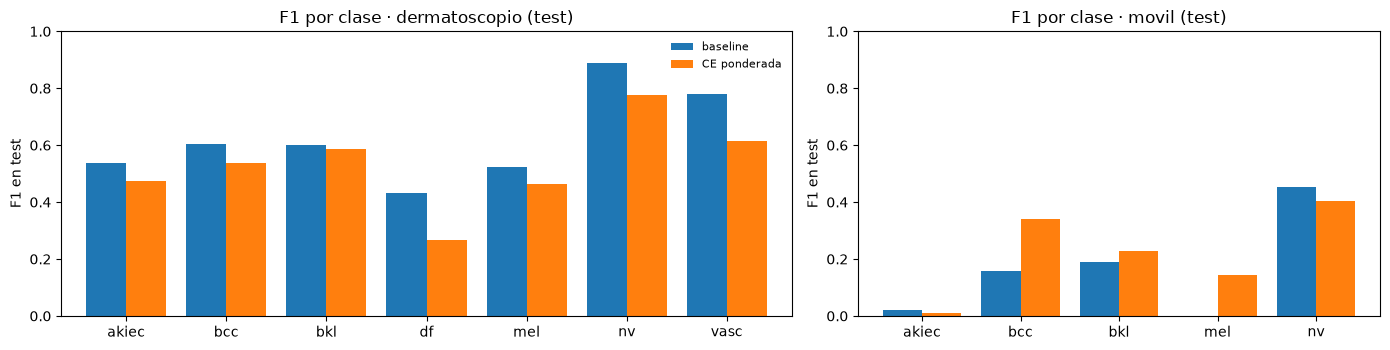

In [43]:
cabeza_ce_pond, esc_ce_pond = entrenar(perdida='ce_ponderada')
display(registrar('CE ponderada', predictor(cabeza_ce_pond, esc_ce_pond)))
comparar('CE ponderada', fichero='u3_ce_ponderada.png')

### 3.2 · Focal loss (nivel 1)

**Qué hace:** multiplica la pérdida de cada ejemplo por (1 − p)<sup>γ</sup>, donde *p* es la probabilidad que el modelo
da a la clase correcta. Los ejemplos fáciles (p alta) casi no cuentan, y el entrenamiento se centra en los difíciles.
La implementación del baseline incluye además los pesos por clase (α), como en el artículo original.
γ se elige con la validación del dermatoscopio.

**Hipótesis:** muchos `nv` son fáciles y dominan la pérdida. La focal loss debería centrarse en los casos dudosos,
como los melanomas que se confunden con nevus, y bajar la tasa `mel→nv` más que la CE ponderada sola.

**Interpretación:** la hipótesis no se cumple: `mel→nv` no baja más que con la CE ponderada (7.6 % frente a 6.7 %).
La curva de γ en validación es casi plana (0.522–0.530, con ±0.009 entre semillas) y γ = 1 empata con la CE ponderada.
En test el F1 por clase es prácticamente el de la CE ponderada. Lo que corrige el desbalanceo es el peso α, que las dos
comparten: con los `nv` ya pesando 60 veces menos, el factor (1 − p)<sup>γ</sup> tiene poco que quitar. 

,mean,std
técnica,,
focal γ=0,0.525,0.008
focal γ=0.5,0.529,0.009
focal γ=1.0,0.530,0.009
focal γ=2.0,0.529,0.008
focal γ=3.0,0.522,0.009
CE ponderada,0.526,0.008


γ elegida (media de 5 semillas): 1.0
Focal γ=1.0: 0.530 ± 0.009 | CE ponderada: 0.526 ± 0.008
Empate: la diferencia está dentro de la variabilidad entre semillas


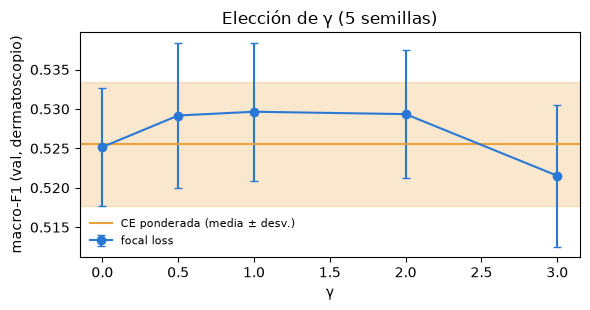

,accuracy,balanced_acc,macro_f1
dominio,,,
dermatoscopio,0.660,0.702,0.535
movil,0.185,0.280,0.210


macro_f1         balanced_acc             accuracy         \
dominio      dermatoscopio  movil dermatoscopio  movil dermatoscopio  movil   
tecnica                                                                       
baseline             0.624  0.165         0.654  0.267         0.775  0.168   
CE ponderada         0.531  0.226         0.711  0.288         0.656  0.200   
focal loss           0.535  0.210         0.702  0.280         0.660  0.185   

                    mel→nv  
dominio      dermatoscopio  
tecnica                     
baseline             0.242  
CE ponderada         0.067  
focal loss           0.076

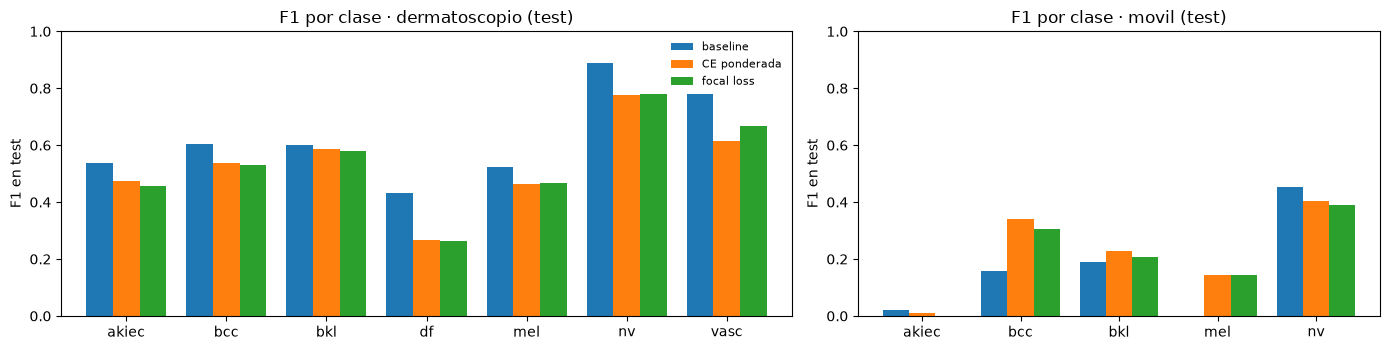

In [44]:
GAMMAS = [0, 0.5, 1.0, 2.0, 3.0]
SEMILLAS = range(5)
X_va_ref = FEATS[MEJOR][va]

def f1_val(semilla, **kw):
    cab, esc = entrenar(semilla=semilla, **kw)
    return medir(y[va], predecir(cab, esc.transform(X_va_ref)), 'dermatoscopio')['macro_f1']

filas = [{'técnica': f'focal γ={g}', 'semilla': s, 'macro_f1_val': f1_val(s, perdida='focal', gamma=g)}
         for g in GAMMAS for s in SEMILLAS]
filas += [{'técnica': 'CE ponderada', 'semilla': s, 'macro_f1_val': f1_val(s, perdida='ce_ponderada')} for s in SEMILLAS]
busqueda = pd.DataFrame(filas)
resumen = busqueda.groupby('técnica', sort=False)['macro_f1_val'].agg(['mean', 'std'])
display(resumen.round(3))

# γ: la de mejor media en validación
focal = resumen.loc[[f'focal γ={g}' for g in GAMMAS]]
GAMMA = float(GAMMAS[int(np.argmax(focal['mean'].to_numpy()))])
mejor, ce = resumen.loc[f'focal γ={GAMMA}'], resumen.loc['CE ponderada']
print(f'γ elegida (media de {len(SEMILLAS)} semillas): {GAMMA}')
print(f'Focal γ={GAMMA}: {mejor["mean"]:.3f} ± {mejor["std"]:.3f} | CE ponderada: {ce["mean"]:.3f} ± {ce["std"]:.3f}')
if abs(mejor['mean'] - ce['mean']) > max(mejor['std'], ce['std']):
    print('La diferencia es mayor que la variabilidad entre semillas')
else:
    print('Empate: la diferencia está dentro de la variabilidad entre semillas')

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.errorbar(GAMMAS, focal['mean'], yerr=focal['std'], marker='o', capsize=3, color='#2a78d6', label='focal loss')
ax.axhline(ce['mean'], color='#e8a33d', label='CE ponderada (media ± desv.)')
ax.axhspan(ce['mean'] - ce['std'], ce['mean'] + ce['std'], color='#e8a33d', alpha=0.25)
ax.set_xlabel('γ'); ax.set_ylabel('macro-F1 (val, dermatoscopio)')
ax.set_title(f'Elección de γ ({len(SEMILLAS)} semillas)'); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(IMG / 'u3_focal_gamma.png', dpi=200, bbox_inches='tight'); plt.show()

cabeza_focal, esc_focal = entrenar(perdida='focal', gamma=GAMMA)
display(registrar('focal loss', predictor(cabeza_focal, esc_focal)))
comparar('CE ponderada', 'focal loss', fichero='u3_focal_loss.png')

### 3.3 · Ajuste de logits (nivel 2)

**Qué hace:** sobre la cabeza del baseline, ya entrenada, resta a cada logit τ · log π<sub>c</sub>, donde π<sub>c</sub>
es la proporción de la clase *c* en el train. Quita la ventaja que tienen las clases frecuentes, sin volver a entrenar
(Menon et al., 2021). τ se elige con la validación del dermatoscopio; τ = 0 es el baseline.

**Hipótesis:** el sesgo hacia `nv` viene de su frecuencia, no de que las features lo separen mejor. Si es así, este
ajuste debería dar un resultado parecido a la CE ponderada sin reentrenar. Como solo cambia la frontera de decisión,
si no mejora, el problema está en la representación y no en el desbalanceo.

**Interpretación:** τ = 0 (el baseline): en validación, la macro-F1 del dermatoscopio baja en cuanto τ > 0. Es lo mismo
que pasó con la CE ponderada: cualquier reequilibrio cambia precisión de `nv` por recall de las clases pequeñas, y la
macro-F1 sale perdiendo. Así que el resultado no señala un problema de representación, sino que el criterio de
selección penaliza reequilibrar. En el móvil sí ayuda (macro-F1 de validación 0.19 → 0.21 con τ entre 0.25 y 0.75),
porque allí `nv` es mucho menos frecuente: corregir la frecuencia del train es justo lo que pide el cambio de dominio.

τ elegida con la validación del dermatoscopio: 0.0


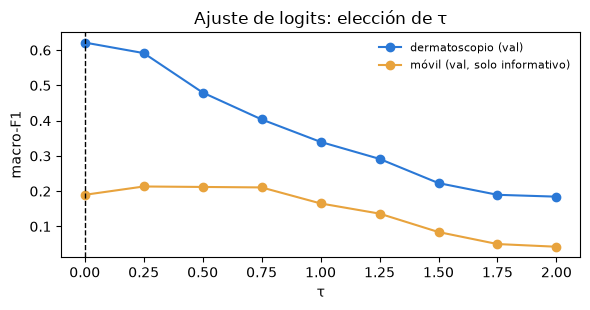

,accuracy,balanced_acc,macro_f1
dominio,,,
dermatoscopio,0.775,0.654,0.624
movil,0.168,0.267,0.165


macro_f1         balanced_acc             accuracy  \
dominio          dermatoscopio  movil dermatoscopio  movil dermatoscopio   
tecnica                                                                    
baseline                 0.624  0.165         0.654  0.267         0.775   
CE ponderada             0.531  0.226         0.711  0.288         0.656   
ajuste de logits         0.624  0.165         0.654  0.267         0.775   

                               mel→nv  
dominio           movil dermatoscopio  
tecnica                                
baseline          0.168         0.242  
CE ponderada      0.200         0.067  
ajuste de logits  0.168         0.242

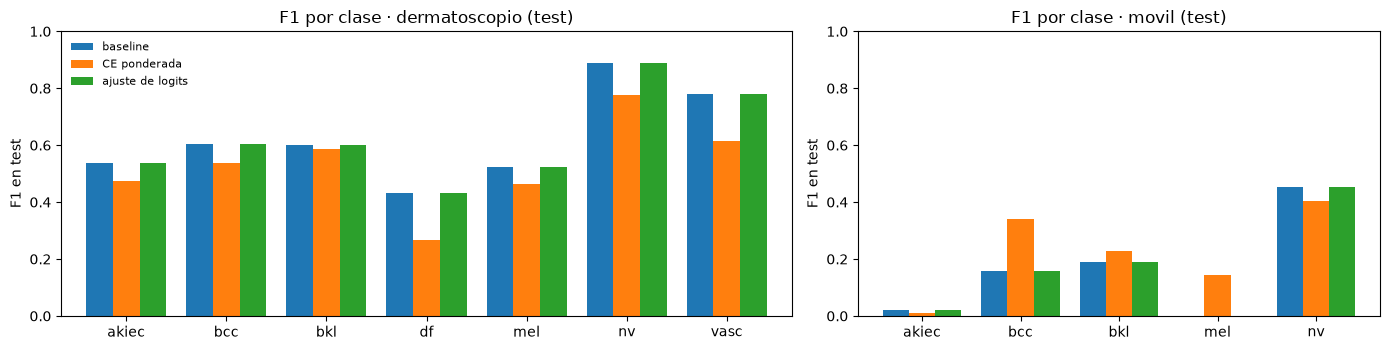

In [45]:
pi = np.bincount(y[tr], minlength=len(clases)) / tr.sum()
LOG_PI = np.log(pi)
X_ref = FEATS[MEJOR]

def predecir_ajustado(m, tau):
    return (calcular_logits(cabeza_base, esc_base.transform(X_ref[m])) - tau * LOG_PI).argmax(1)

TAUS = np.round(np.arange(0, 2.01, 0.25), 2)
curva_tau = pd.DataFrame([{'tau': t,
                           'macro_f1_val_dermatoscopio': medir(y[va], predecir_ajustado(va, t), 'dermatoscopio')['macro_f1'],
                           'macro_f1_val_movil': medir(y[va_d], predecir_ajustado(va_d, t), 'movil')['macro_f1']}
                          for t in TAUS])
TAU = float(curva_tau.loc[curva_tau['macro_f1_val_dermatoscopio'].idxmax(), 'tau'])
print('τ elegida con la validación del dermatoscopio:', TAU)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(curva_tau['tau'], curva_tau['macro_f1_val_dermatoscopio'], 'o-', label='dermatoscopio (val)', color='#2a78d6')
ax.plot(curva_tau['tau'], curva_tau['macro_f1_val_movil'], 'o-', label='móvil (val, solo informativo)', color='#e8a33d')
ax.axvline(TAU, color='black', ls='--', lw=1)
ax.set_xlabel('τ'); ax.set_ylabel('macro-F1'); ax.set_title('Ajuste de logits: elección de τ'); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(IMG / 'u3_ajuste_logits_tau.png', dpi=200, bbox_inches='tight'); plt.show()

display(registrar('ajuste de logits', lambda m: predecir_ajustado(m, TAU)))
comparar('CE ponderada', 'ajuste de logits', fichero='u3_ajuste_logits.png')

## 4 · Compensar con los datos

### 4.1 · Batches balanceados (nivel 1)

**Qué hace:** cada batch se construye con el mismo número de ejemplos de cada clase (256 / 7 ≈ 36), repitiendo los
de las clases pequeñas. La pérdida no cambia: lo que cambia es qué ve el modelo en cada paso.

**Hipótesis:** el efecto debería parecerse al de la CE ponderada, porque las dos igualan el peso de las clases.
Pero repetir las mismas 80 imágenes de `df` muchas veces puede llevar a memorizarlas: es posible que mejore menos que
la CE ponderada en las clases más pequeñas.

**Interpretación:** la hipótesis se cumple. El efecto va en la misma dirección que la CE ponderada, pero es algo peor
en casi todas las clases (macro-F1 0.497 frente a 0.531), y sobre todo en las más pequeñas: `df` (0.22 frente a 0.26)
y `vasc` (0.54 frente a 0.62), que son las que más se repiten. Es la que más baja `mel→nv` (5.4 %), pero en el móvil
no acierta ningún melanoma. Repetir los mismos ejemplos no aporta información nueva: la CE ponderada consigue lo mismo
sin repetirlos.

,accuracy,balanced_acc,macro_f1
dominio,,,
dermatoscopio,0.636,0.674,0.497
movil,0.168,0.246,0.172


macro_f1         balanced_acc             accuracy  \
dominio             dermatoscopio  movil dermatoscopio  movil dermatoscopio   
tecnica                                                                       
baseline                    0.624  0.165         0.654  0.267         0.775   
CE ponderada                0.531  0.226         0.711  0.288         0.656   
batches balanceados         0.497  0.172         0.674  0.246         0.636   

                                  mel→nv  
dominio              movil dermatoscopio  
tecnica                                   
baseline             0.168         0.242  
CE ponderada         0.200         0.067  
batches balanceados  0.168         0.054

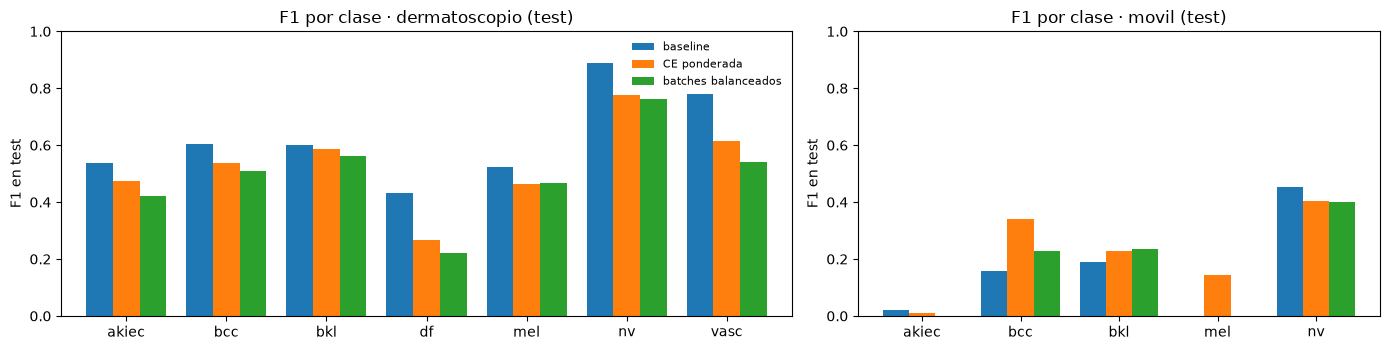

In [46]:
cabeza_bal, esc_bal = entrenar(muestreo='batch_balanceado')
display(registrar('batches balanceados', predictor(cabeza_bal, esc_bal)))
comparar('CE ponderada', 'batches balanceados', fichero='u3_batches_balanceados.png')

### 4.2 · Mezcla de imágenes (nivel 2)

**Qué hace (mixup):** se generan imágenes nuevas combinando dos del train, x = λ·x<sub>1</sub> + (1 − λ)·x<sub>2</sub>,
con su etiqueta mezclada en la misma proporción, y = λ·y<sub>1</sub> + (1 − λ)·y<sub>2</sub>. λ sigue una Beta(0,4; 0,4).

**Cómo se aplica aquí:** como el extractor está congelado, las mezclas se generan **una sola vez**, se extraen sus
features con el extractor de referencia y se guardan en `trabajo/features/<modelo>_mezcla.pt`. La cabeza lineal se
entrena con las features originales más las de las mezclas. La primera imagen de cada pareja se elige de forma
equilibrada por clase y la segunda al azar, para que las clases pequeñas aparezcan en las mezclas.

**Control:** para separar el efecto de *mezclar* del de *equilibrar las clases*, se entrena también con las mismas
primeras imágenes sin mezclar (sus features originales, con su etiqueta). La diferencia entre las dos es lo que aporta
la mezcla.

**Hipótesis:** las mezclas crean ejemplos intermedios entre clases y suavizan la frontera de decisión. Como el extractor
no es lineal, las features de una imagen mezclada no son la mezcla de las features: dan información nueva. Debería
mejorar las clases que se confunden entre sí (`mel` y `nv`, `akiec` y `bkl`) más que el control.

**Interpretación:** es la única técnica que mejora la macro-F1 del dermatoscopio (0.624 → 0.642), y el control sin
mezclar no (0.622): la mejora viene de mezclar, no de equilibrar. Sube sobre todo `bcc`, `bkl` y `df`, y baja `vasc`.
Pero no se cumple la parte de `mel`/`nv`: `mel→nv` sube al 26 %. En el móvil es la peor (0.140), porque predice aún más
`nv`. Ojo: es una sola semilla, y +0.018 es del orden de dos desviaciones entre semillas de la focal (±0.009).

La extracción tarda más o menos lo mismo que la del extractor en el baseline la primera vez; después se carga de disco.

Features de las mezclas: (7007, 512)


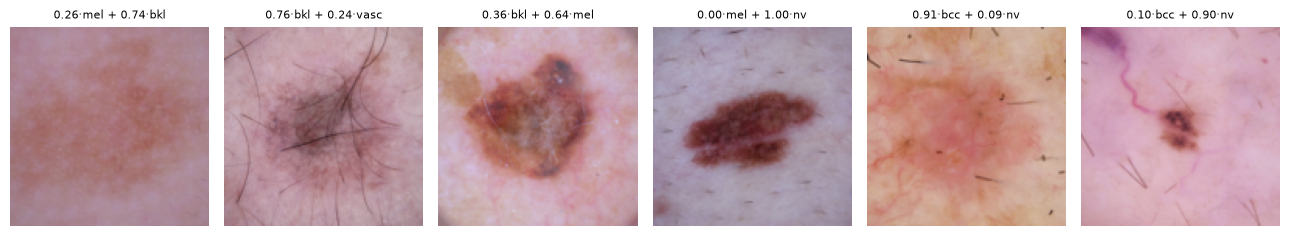

In [47]:
N_MEZCLAS = int(tr.sum())          # tantas mezclas como imágenes de train
ALFA = 0.4
rng = np.random.default_rng(SEMILLA)
idx_tr = np.where(tr)[0]
por_clase = [idx_tr[y[idx_tr] == c] for c in clases.index]
c1 = rng.integers(0, len(clases), N_MEZCLAS)                    # clase de la 1.ª imagen: equilibrada
i1 = np.array([rng.choice(por_clase[c]) for c in c1])
i2 = rng.choice(idx_tr, N_MEZCLAS)                              # 2.ª imagen: al azar
lam = rng.beta(ALFA, ALFA, N_MEZCLAS).astype(np.float32)

class Mezclas(Dataset):
    def __init__(self, r1, r2, lam, transform):
        self.r1, self.r2, self.lam, self.transform = list(r1), list(r2), lam, transform
    def __len__(self):
        return len(self.r1)
    def __getitem__(self, i):
        a = Image.open(self.r1[i]).convert('RGB')
        b = Image.open(self.r2[i]).convert('RGB').resize(a.size)
        return self.transform(Image.blend(b, a, float(self.lam[i])))    # lam·a + (1 − lam)·b

fichero = TRABAJO / 'features' / f'{MEJOR}_mezcla.pt'
guardado = torch.load(fichero, weights_only=False) if fichero.exists() else None   # fichero creado por este notebook
if guardado is not None and np.array_equal(guardado['i1'], i1):
    F_MEZ = guardado['feats'].numpy()
else:
    modelo, tf = cargar_modelo(MEJOR)
    modelo = modelo.to(DEVICE).eval()
    salida = []
    with torch.no_grad():
        for x in DataLoader(Mezclas(tabla['ruta'].iloc[i1], tabla['ruta'].iloc[i2], lam, tf),
                            batch_size=256, num_workers=NUM_WORKERS):
            with torch.autocast('cuda', enabled=DEVICE == 'cuda'):
                salida.append(modelo(x.to(DEVICE)).float().cpu())
    F_MEZ = torch.cat(salida).numpy()
    torch.save({'feats': torch.from_numpy(F_MEZ), 'i1': i1, 'i2': i2, 'lam': lam}, fichero)
    del modelo

Y_MEZ = np.zeros((N_MEZCLAS, len(clases)), dtype=np.float32)
np.add.at(Y_MEZ, (np.arange(N_MEZCLAS), y[i1]), lam)
np.add.at(Y_MEZ, (np.arange(N_MEZCLAS), y[i2]), 1 - lam)
assert np.allclose(Y_MEZ.sum(1), 1)
print('Features de las mezclas:', F_MEZ.shape)

# Ejemplos de mezclas
fig, axs = plt.subplots(1, 6, figsize=(13, 2.6))
for ax, j in zip(axs, rng.choice(N_MEZCLAS, 6, replace=False)):
    a = Image.open(tabla['ruta'].iloc[i1[j]]).convert('RGB')
    b = Image.open(tabla['ruta'].iloc[i2[j]]).convert('RGB').resize(a.size)
    ax.imshow(Image.blend(b, a, float(lam[j]))); ax.axis('off')
    ax.set_title(f"{lam[j]:.2f}·{cod[y[i1[j]]]} + {1 - lam[j]:.2f}·{cod[y[i2[j]]]}", fontsize=8)
plt.tight_layout(); plt.savefig(IMG / 'u3_mezcla_ejemplos.png', dpi=200, bbox_inches='tight'); plt.show()

,accuracy,balanced_acc,macro_f1
dominio,,,
dermatoscopio,0.797,0.660,0.642
movil,0.159,0.255,0.140


,accuracy,balanced_acc,macro_f1
dominio,,,
dermatoscopio,0.772,0.688,0.622
movil,0.176,0.275,0.172


macro_f1         balanced_acc             accuracy  \
dominio               dermatoscopio  movil dermatoscopio  movil dermatoscopio   
tecnica                                                                         
baseline                      0.624  0.165         0.654  0.267         0.775   
control (sin mezclar)         0.622  0.172         0.688  0.275         0.772   
mezcla de imágenes            0.642  0.140         0.660  0.255         0.797   

                                    mel→nv  
dominio                movil dermatoscopio  
tecnica                                     
baseline               0.168         0.242  
control (sin mezclar)  0.176         0.202  
mezcla de imágenes     0.159         0.260

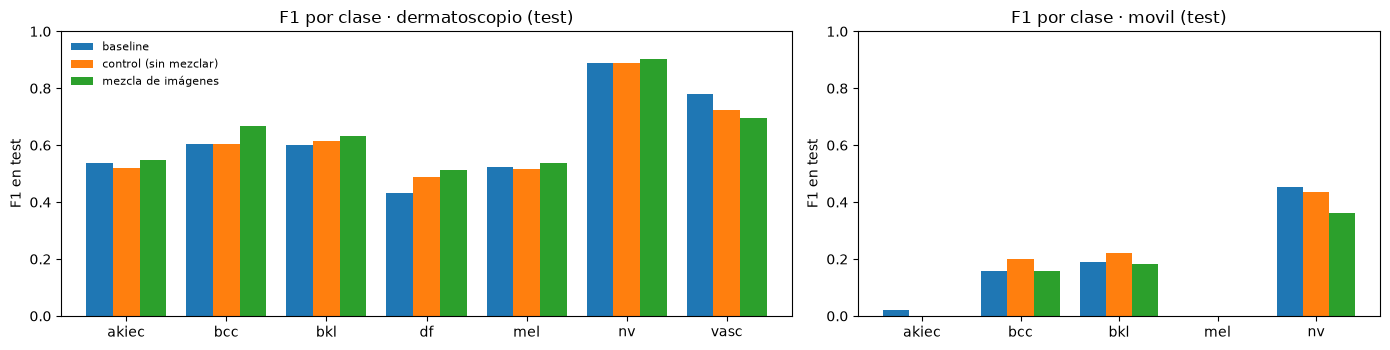

In [48]:
X_ref = FEATS[MEJOR]
Y_orig = np.eye(len(clases), dtype=np.float32)[y[tr]]

# Mezcla: originales + mezclas
sembrar()
cabeza_mez = entrenar_cabeza_suave(esc_base.transform(np.vstack([X_ref[tr], F_MEZ])), np.vstack([Y_orig, Y_MEZ]), len(clases))
display(registrar('mezcla de imágenes', lambda m: predecir(cabeza_mez, esc_base.transform(X_ref[m]))))

# Control: originales + las mismas primeras imágenes sin mezclar
sembrar()
cabeza_ctrl = entrenar_cabeza_suave(esc_base.transform(np.vstack([X_ref[tr], X_ref[i1]])),
                                    np.vstack([Y_orig, np.eye(len(clases), dtype=np.float32)[y[i1]]]), len(clases))
display(registrar('control (sin mezclar)', lambda m: predecir(cabeza_ctrl, esc_base.transform(X_ref[m]))))

comparar('control (sin mezclar)', 'mezcla de imágenes', fichero='u3_mezcla.png')

## 5 · Evaluar una representación: t-SNE

**Qué hace:** proyecta las features de cada extractor a 2 dimensiones (t-SNE) para ver cómo organiza las imágenes:
si las clases forman grupos separados y si los dos dominios se mezclan o quedan aparte. Se usan los tests de los dos
dominios. Como el t-SNE solo es una visualización, se acompaña de una medida numérica, el **coeficiente de silueta**
(de −1 a 1; cuanto más alto, mejor separadas están las clases), calculado sobre las features originales:
- por clase en el test del dermatoscopio,
- solo entre `mel` y `nv`, la confusión más grave del baseline,
- por dominio: si es alto, el extractor separa el dermatoscopio del móvil (mala señal para la U4).

**Hipótesis:** el extractor con mejor linear probe debería ser el que mejor separa las clases. Si `mel` y `nv` se
solapan en todos los extractores, la confusión `mel→nv` es un problema de representación y las técnicas de
desbalanceo no la resolverán del todo.

**Interpretación:** ningún extractor separa bien las clases: la silueta por clase está en torno a 0 en los tres, y la
de `mel` frente a `nv` no pasa de 0.10 (DINOv2). La confusión `mel→nv` es, por tanto, en buena parte un problema de
representación, lo que explica que las técnicas de pérdida y de datos solo cambien unos errores por otros. DINOv2, el de
mejor linear probe en test, es también el que mejor separa, como se esperaba. Los tres colocan el móvil en una isla
aparte, y CLIP es el que más lo separa (0.37 frente a 0.25 y 0.16), que es el que más cae en el móvil: mala señal para
la U4 si se sigue con CLIP.

Tarda unos segundos por extractor.

,silueta clases (dermatoscopio),silueta mel vs nv (dermatoscopio),silueta por dominio,"macro-F1 linear probe (dermatoscopio, test)","macro-F1 linear probe (movil, test)"
extractor,,,,,
clip_vitb32,-0.015,0.034,0.374,0.613,0.169
dinov2_vits14,0.017,0.098,0.246,0.629,0.237
resnet50,-0.037,0.058,0.161,0.513,0.232


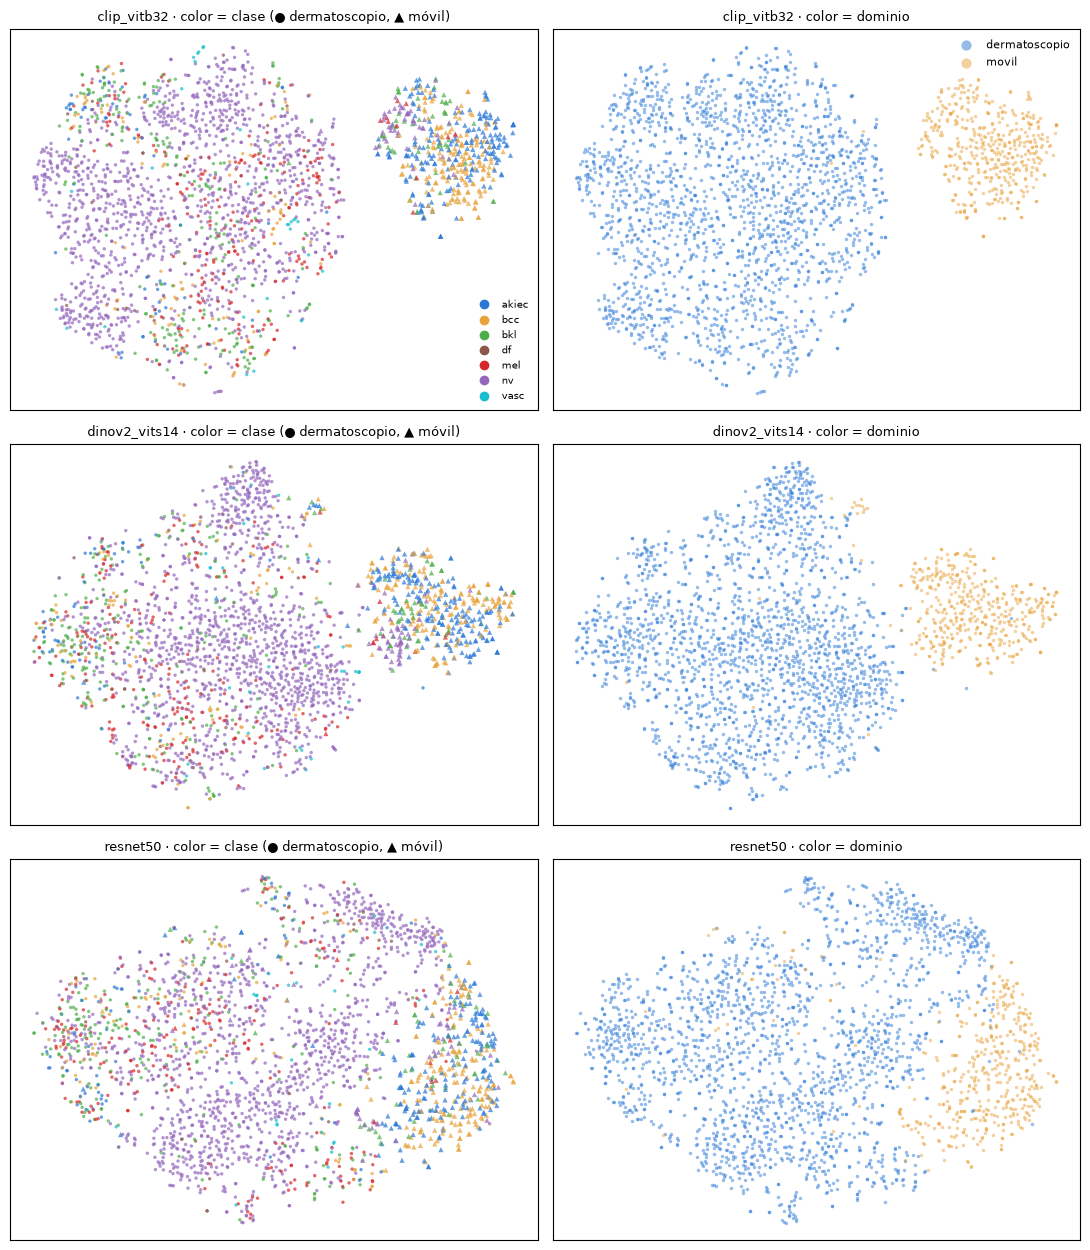

In [ ]:
idx_vis = np.where(te | te_d)[0]
dom_vis = tabla['dominio'].to_numpy()[idx_vis]
y_vis = y[idx_vis]
colores = dict(zip(cod, ['#2a78d6', '#e8a33d', '#4daf4a', '#8c564b', '#d62728', '#9467bd', '#17becf']))

TSNE_XY, silueta = {}, []
for nombre, X in FEATS.items():
    Xn = normalizar(X[idx_vis])
    TSNE_XY[nombre] = TSNE(n_components=2, perplexity=30, init='pca', random_state=SEMILLA).fit_transform(Xn)
    o = dom_vis == 'dermatoscopio'
    mn = o & np.isin(y_vis, [ID['mel'], ID['nv']])
    silueta.append({'extractor': nombre,
                    'silueta clases (dermatoscopio)': silhouette_score(Xn[o], y_vis[o], metric='cosine'),
                    'silueta mel vs nv (dermatoscopio)': silhouette_score(Xn[mn], y_vis[mn], metric='cosine'),
                    'silueta por dominio': silhouette_score(Xn, dom_vis, metric='cosine')})
silueta = pd.DataFrame(silueta).set_index('extractor')
previo = TRABAJO / 'resultados_baseline.csv'
if previo.exists():
    p = pd.read_csv(previo)
    for dom in ('dermatoscopio', 'movil'):
        silueta[f'macro-F1 linear probe ({dom}, test)'] = p[(p['dominio'] == dom) & (p['particion'] == 'test')].set_index('modelo')['macro_f1']
display(silueta.round(3))

fig, axs = plt.subplots(len(FEATS), 2, figsize=(11, 4.2 * len(FEATS)), squeeze=False)
for fila, (nombre, Z) in zip(axs, TSNE_XY.items()):
    for dom, marca in (('dermatoscopio', 'o'), ('movil', '^')):
        s = dom_vis == dom
        fila[0].scatter(Z[s, 0], Z[s, 1], c=[colores[cod[c]] for c in y_vis[s]], s=6 if dom == 'dermatoscopio' else 14,
                        marker=marca, alpha=0.7, linewidths=0)
        fila[1].scatter(Z[s, 0], Z[s, 1], s=6, alpha=0.5, linewidths=0, label=dom,
                        color='#2a78d6' if dom == 'dermatoscopio' else '#e8a33d')
    fila[0].set_title(f'{nombre} · color = clase (● dermatoscopio, ▲ móvil)', fontsize=9)
    fila[1].set_title(f'{nombre} · color = dominio', fontsize=9)
    for ax in fila:
        ax.set_xticks([]); ax.set_yticks([])
axs[0, 0].legend(handles=[plt.Line2D([], [], marker='o', ls='', color=colores[c], label=c) for c in cod],
                 fontsize=7, frameon=False, loc='best')
axs[0, 1].legend(fontsize=8, frameon=False, markerscale=3)
plt.tight_layout(); plt.savefig(IMG / 'u3_tsne.png', dpi=150, bbox_inches='tight'); plt.show()
silueta.to_csv(U3 / 'silueta.csv')

leyenda = ([plt.Line2D([], [], marker='o', ls='', color=colores[c], label=c) for c in cod] +
           [plt.Line2D([], [], marker='o', ls='', color='#898781', label='dermatoscopio'),
            plt.Line2D([], [], marker='^', ls='', color='#898781', label='móvil')])
for nombre, Z in TSNE_XY.items():
    fig, ax = plt.subplots(figsize=(6, 5))
    for dom, marca in (('dermatoscopio', 'o'), ('movil', '^')):
        s = dom_vis == dom
        ax.scatter(Z[s, 0], Z[s, 1], c=[colores[cod[c]] for c in y_vis[s]], s=6 if dom == 'dermatoscopio' else 14,
                   marker=marca, alpha=0.7, linewidths=0)
    ax.set_title(f't-SNE · {nombre}', fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    ax.legend(handles=leyenda, fontsize=7, frameon=False, loc='center left', bbox_to_anchor=(1, 0.5))
    plt.tight_layout(); plt.savefig(IMG / f'u3_tsne_{nombre}.png', dpi=150, bbox_inches='tight'); plt.show()

## 6 · Pocos datos

### 6.1 · CLIP zero-shot (nivel 1)

**Qué hace:** CLIP lleva imágenes y textos al mismo espacio. Para clasificar sin ningún ejemplo, se escribe una frase
por clase («a dermoscopy image of melanoma», …), se codifica con el codificador de texto de CLIP y cada imagen se
asigna a la frase más parecida (similitud coseno). Se promedian varias plantillas de frase, que suele dar mejores
resultados que una sola. No se entrena nada ni se usa ninguna etiqueta.

**Hipótesis:** CLIP se entrenó con imágenes de internet, donde casi no hay imágenes de dermatoscopio y los términos
médicos son raros, así que en términos absolutos debería funcionar mal. Pero no se entrena con el dermatoscopio, así
que no hereda el sesgo hacia `nv`, y las fotos de móvil se parecen más a las de internet: es posible que **caiga menos
al pasar al móvil** que el baseline, o incluso que funcione mejor allí que en el dermatoscopio.

**Interpretación:** la hipótesis se cumple. En el dermatoscopio es muy malo (macro-F1 0.114; `df` y `vasc` en 0), y en
el móvil funciona mejor que el baseline (accuracy 0.349 frente a 0.168). Pero no es que sepa dermatología: predice
casi todo `bcc` (F1 0.68), que es el 37 % del test del móvil, y ningún `nv`. Eligiendo solo entre las 5 clases del
móvil empata con el baseline (0.186 frente a 0.188). Su ventaja es no haber aprendido las proporciones del
dermatoscopio.

,accuracy,balanced_acc,macro_f1
dominio,,,
dermatoscopio,0.179,0.202,0.114
movil,0.349,0.380,0.178


Macro-F1 en test del móvil eligiendo solo entre sus 5 clases: {'baseline': 0.188, 'CLIP zero-shot': 0.186}


macro_f1         balanced_acc             accuracy         \
dominio        dermatoscopio  movil dermatoscopio  movil dermatoscopio  movil   
tecnica                                                                         
baseline               0.624  0.165         0.654  0.267         0.775  0.168   
CLIP zero-shot         0.114  0.178         0.202  0.380         0.179  0.349   

                      mel→nv  
dominio        dermatoscopio  
tecnica                       
baseline               0.242  
CLIP zero-shot         0.202

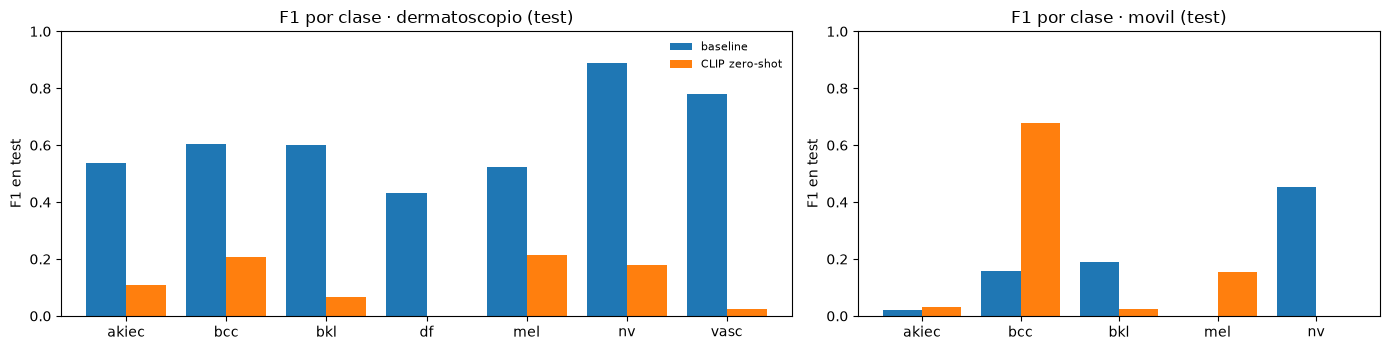

In [50]:
import open_clip
modelo_clip, _, _ = open_clip.create_model_and_transforms('ViT-B-32', pretrained='laion2b_s34b_b79k')
tok = open_clip.get_tokenizer('ViT-B-32')
PLANTILLAS = ['a dermoscopy image of {}.', 'a dermatoscopic photo of {}.', 'a close-up photo of {} on the skin.',
              'a clinical photo of a skin lesion: {}.', 'a photo of {}, a type of skin lesion.']

with torch.no_grad():
    T_txt = []
    for nombre_en in clases['ingles']:
        e = modelo_clip.encode_text(tok([p.format(nombre_en) for p in PLANTILLAS])).float()
        e = e / e.norm(dim=1, keepdim=True)
        T_txt.append(e.mean(0))                          # promedio de plantillas
    T_txt = torch.stack(T_txt)
    T_txt = (T_txt / T_txt.norm(dim=1, keepdim=True)).numpy()
del modelo_clip

SIM_ZS = normalizar(FEATS['clip_vitb32']) @ T_txt.T       # similitud de cada imagen con cada clase
display(registrar('CLIP zero-shot', lambda m: SIM_ZS[m].argmax(1), modelo='clip_vitb32'))

# Variante: en el móvil, elegir solo entre las 5 clases que existen allí. Para que la comparación sea justa,
# se aplica la misma restricción al baseline
solo5 = lambda S: np.array(CLASES_DESTINO)[S[:, CLASES_DESTINO].argmax(1)]
logits_base_movil = calcular_logits(cabeza_base, esc_base.transform(X_ref[te_d]))
print('Macro-F1 en test del móvil eligiendo solo entre sus 5 clases:',
      {'baseline': round(medir(y[te_d], solo5(logits_base_movil), 'movil')['macro_f1'], 3),
       'CLIP zero-shot': round(medir(y[te_d], solo5(SIM_ZS[te_d]), 'movil')['macro_f1'], 3)})

comparar('CLIP zero-shot', fichero='u3_clip_zero_shot.png')

### 6.2 · Curva de 1 a 20 melanomas

**Qué hace:** se entrena el clasificador con todas las imágenes del resto de clases, pero con solo *k* melanomas
elegidos al azar (*k* = 1, 2, 5, 10, 20), y se mide el F1 de `mel` en el test del dermatoscopio. Cada *k* se repite
con 5 semillas, porque el resultado depende de qué melanomas toquen. Se hace con cada extractor, y como referencia
se marcan el resultado con los 779 melanomas y, para CLIP, el zero-shot (*k* = 0).

Se usa la **CE ponderada**: con la CE normal y un solo melanoma entre ~6 000 imágenes, el modelo nunca predice
`mel` y la curva no mide nada.

**Hipótesis:** el F1 de `mel` debería subir rápido con los primeros ejemplos y estabilizarse. El extractor cuya curva
sube antes es el que mejor representa los melanomas con pocos datos. Es la situación del móvil, donde solo hay
31 melanomas de entrenamiento.

**Interpretación:** la hipótesis no se cumple: el F1 de `mel` sube despacio y no se estabiliza. Con 20 melanomas llega
a 0.30 (CLIP) y 0.32 (DINOv2), lejos de los ~0.48 que se obtienen con los 779. CLIP y DINOv2 van igual, y ResNet se
queda muy por debajo (0.12 con 20). El zero-shot de CLIP (0.215, sin ningún ejemplo) equivale a tener entre 10 y 20
melanomas etiquetados. Con los 31 melanomas del móvil cabe esperar, como mucho, un F1 de `mel` modesto.

Son 4 extractores × 5 valores de *k* × 5 semillas = 100 entrenamientos: puede tardar varios minutos.
Los resultados se guardan en `trabajo/u3/curva_melanomas.csv` y no se repiten si el fichero existe.

mean                                std                \
extractor clip_vitb32 dinov2_vits14 resnet50 clip_vitb32 dinov2_vits14   
k                                                                        
1               0.012         0.010    0.012       0.010         0.007   
2               0.037         0.030    0.017       0.013         0.022   
5               0.116         0.113    0.052       0.035         0.050   
10              0.184         0.185    0.069       0.033         0.042   
20              0.303         0.322    0.123       0.015         0.023   

                    
extractor resnet50  
k                   
1            0.005  
2            0.015  
5            0.031  
10           0.015  
20           0.008

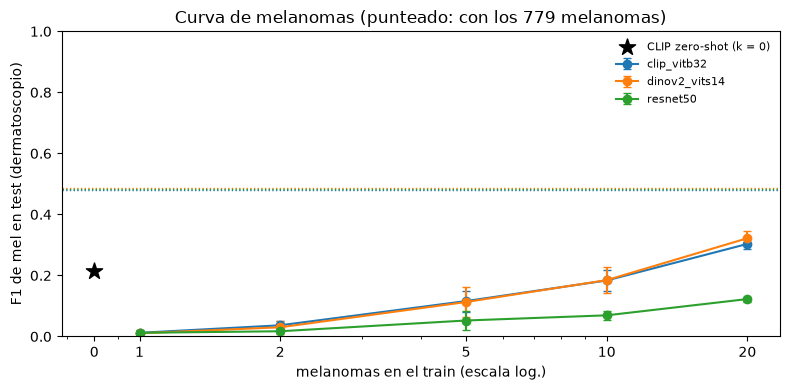

In [51]:
KS, SEMILLAS = [1, 2, 5, 10, 20], range(5)
MEL = ID['mel']
idx_mel, idx_resto = idx_tr[y[idx_tr] == MEL], idx_tr[y[idx_tr] != MEL]
f1_mel = lambda yt, p: f1_score(yt, p, labels=[MEL], average='macro', zero_division=0)

fichero = U3 / 'curva_melanomas.csv'
if fichero.exists() and set(pd.read_csv(fichero)['extractor']) == set(FEATS):
    curva = pd.read_csv(fichero)
else:
    filas = []
    for nombre, X in FEATS.items():
        for k in KS + [len(idx_mel)]:
            for s in (SEMILLAS if k < len(idx_mel) else [0]):
                elegidos = np.random.default_rng(s).choice(idx_mel, k, replace=False)
                idx = np.concatenate([idx_resto, elegidos])
                esc = StandardScaler().fit(X[idx])
                sembrar(s)
                cab = entrenar_cabeza(esc.transform(X[idx]), y[idx], len(clases), perdida='ce_ponderada')
                p = predecir(cab, esc.transform(X[te]))
                filas.append({'extractor': nombre, 'k': k, 'semilla': s, 'f1_mel': f1_mel(y[te], p),
                              'macro_f1': medir(y[te], p, 'dermatoscopio')['macro_f1']})
        print(nombre, 'hecho')
    curva = pd.DataFrame(filas)
    curva.to_csv(fichero, index=False)

resumen = curva[curva['k'] < len(idx_mel)].groupby(['extractor', 'k'])['f1_mel'].agg(['mean', 'std']).unstack(0)
display(resumen.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
for i, nombre in enumerate(FEATS):
    c = curva[(curva['extractor'] == nombre) & (curva['k'] < len(idx_mel))].groupby('k')['f1_mel'].agg(['mean', 'std'])
    color = plt.cm.tab10(i)
    ax.errorbar(c.index, c['mean'], yerr=c['std'], marker='o', capsize=3, color=color, label=nombre)
    completo = curva[(curva['extractor'] == nombre) & (curva['k'] == len(idx_mel))]['f1_mel'].iloc[0]
    ax.axhline(completo, color=color, ls=':', lw=1)
zs = f1_mel(y[te], PREDS[('CLIP zero-shot', 'dermatoscopio')])
ax.scatter([0.8], [zs], marker='*', s=150, color='black', zorder=5, label='CLIP zero-shot (k = 0)')
ax.set_xscale('log'); ax.set_xticks([0.8] + KS, ['0'] + [str(k) for k in KS])
ax.set_xlabel('melanomas en el train (escala log.)'); ax.set_ylabel('F1 de mel en test (dermatoscopio)')
ax.set_title(f'Curva de melanomas (punteado: con los {len(idx_mel)} melanomas)'); ax.set_ylim(0, 1)
ax.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig(IMG / 'u3_curva_melanomas.png', dpi=200, bbox_inches='tight'); plt.show()

## 7 · Comparación de todas las técnicas

Todas las técnicas frente al baseline, en test. La tabla se guarda en `trabajo/u3/resultados_u3.csv`.

macro_f1         balanced_acc             accuracy  \
dominio               dermatoscopio  movil dermatoscopio  movil dermatoscopio   
tecnica                                                                         
baseline                      0.624  0.165         0.654  0.267         0.775   
CE ponderada                  0.531  0.226         0.711  0.288         0.656   
focal loss                    0.535  0.210         0.702  0.280         0.660   
ajuste de logits              0.624  0.165         0.654  0.267         0.775   
batches balanceados           0.497  0.172         0.674  0.246         0.636   
mezcla de imágenes            0.642  0.140         0.660  0.255         0.797   
control (sin mezclar)         0.622  0.172         0.688  0.275         0.772   
CLIP zero-shot                0.114  0.178         0.202  0.380         0.179   

                                    F1 mel        mel→nv  \
dominio                movil dermatoscopio dermatoscopio   
tecnica                                                    
baseline               0.168         0.522         0.242   
CE ponderada           0.200         0.462         0.067   
focal loss             0.185         0.468         0.076   
ajuste de logits       0.168         0.522         0.242   
batches balanceados    0.168         0.468         0.054   
mezcla de imágenes     0.159         0.536         0.260   
control (sin mezclar)  0.176         0.517         0.202   
CLIP zero-shot         0.349         0.215         0.202   

                      Δ macro-F1 vs baseline  
dominio                        dermatoscopio  
tecnica                                       
baseline                               0.000  
CE ponderada                          -0.093  
focal loss                            -0.089  
ajuste de logits                       0.000  
batches balanceados                   -0.127  
mezcla de imágenes                     0.018  
control (sin mezclar)                 -0.002  
CLIP zero-shot                        -0.509

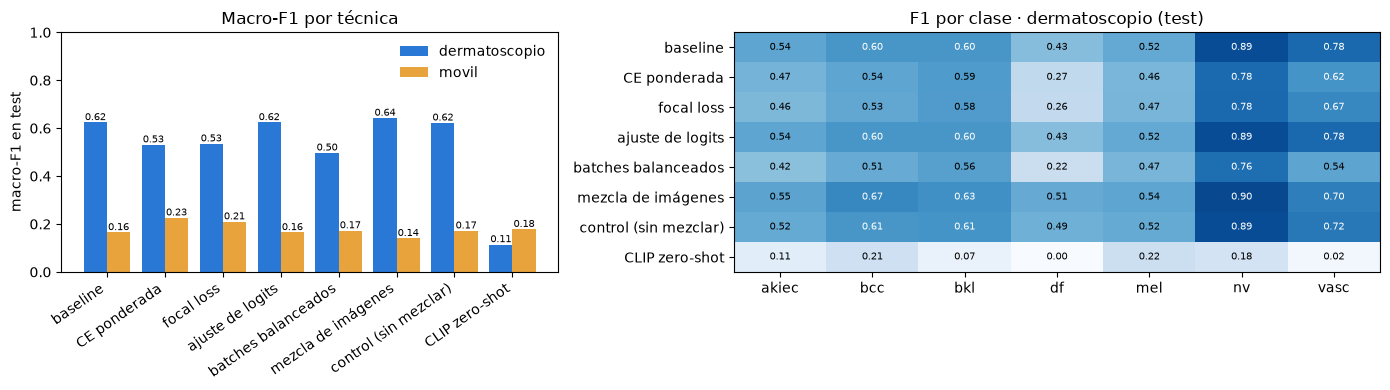

In [52]:
res = pd.DataFrame(RESULTADOS)
res.to_csv(U3 / 'resultados_u3.csv', index=False)
orden = list(dict.fromkeys(res['tecnica']))
final = (res[res['particion'] == 'test']
         .pivot(index='tecnica', columns='dominio', values=['macro_f1', 'balanced_acc', 'accuracy']).reindex(orden))
final[('F1 mel', 'dermatoscopio')] = [f1_por_clase(t, 'dermatoscopio')['mel'] for t in orden]
final[('mel→nv', 'dermatoscopio')] = [tasa(t, 'dermatoscopio', 'mel', 'nv') for t in orden]
base = final.loc['baseline', ('macro_f1', 'dermatoscopio')]
final[('Δ macro-F1 vs baseline', 'dermatoscopio')] = final[('macro_f1', 'dermatoscopio')] - base
display(final.round(3))

fig, axs = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={'width_ratios': [1, 1.3]})
x = np.arange(len(orden))
for k, (dom, color) in enumerate([('dermatoscopio', '#2a78d6'), ('movil', '#e8a33d')]):
    v = final[('macro_f1', dom)].to_numpy()
    b = axs[0].bar(x + (k - .5) * .4, v, .4, color=color, label=dom)
    axs[0].bar_label(b, labels=[f'{a:.2f}' for a in v], fontsize=7)
axs[0].set_xticks(x, orden, rotation=35, ha='right'); axs[0].set_ylabel('macro-F1 en test'); axs[0].set_ylim(0, 1)
axs[0].legend(frameon=False); axs[0].set_title('Macro-F1 por técnica')

f1 = pd.DataFrame({t: f1_por_clase(t, 'dermatoscopio') for t in orden}).T
im = axs[1].imshow(f1.to_numpy(), cmap='Blues', vmin=0, vmax=1, aspect='auto')
for i in range(f1.shape[0]):
    for j in range(f1.shape[1]):
        axs[1].text(j, i, f'{f1.iat[i, j]:.2f}', ha='center', va='center', fontsize=7,
                    color='white' if f1.iat[i, j] > .6 else 'black')
axs[1].set_xticks(range(f1.shape[1]), f1.columns); axs[1].set_yticks(range(len(orden)), orden)
axs[1].set_title('F1 por clase · dermatoscopio (test)')
plt.tight_layout(); plt.savefig(IMG / 'u3_comparacion.png', dpi=200, bbox_inches='tight'); plt.show()

## 8 · Conclusión de la unidad 3

*(Escribir tras ejecutar. Preguntas que conviene responder:)*

- ¿Qué técnica mejora más la macro-F1 del dermatoscopio? ¿Mejora a costa de alguna clase?
- ¿Las técnicas de pérdida y las de datos tienen un efecto parecido, como se esperaba?
- ¿Baja la confusión `mel→nv`? Si no baja con ninguna técnica de desbalanceo, ¿lo explica el t-SNE (representación)?
- ¿Qué pasa en el móvil? ¿Alguna técnica mejora el origen y empeora el destino (por predecir `df` o `vasc`)?
- ¿Cuántos melanomas hacen falta según la curva, y qué extractor aprende antes?
- ¿Qué se lleva a la U4: qué técnica y qué extractor?